# Практика 5. Градиенты, границы и преобразование Хафа

**Курс:** Обработка изображений

На практике мы:
- оценим конечные разности и построим градиент (модуль и направление);
- увидим, почему дифференцирование усиливает шум, и сравним разность с Собелем;
- применим производную гауссиана и исследуем выбор $\sigma$;
- найдём пересечения нуля LoG;
- разберём ключевые шаги Кэнни: NMS и гистерезис;
- реализуем голосование Хафа для прямых и найдём окружности;
- выровняем наклонённый скан документа.

Работаем с `skimage.data` и синтетическими массивами NumPy — без внешних файлов.
Сначала сформулируйте ожидаемый результат, затем запускайте код и объясняйте наблюдение.


## 0. Импорты и вспомогательные функции


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage as ndi
from skimage import color, data, feature, filters, transform, util

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.14.0
NumPy: 2.1.3


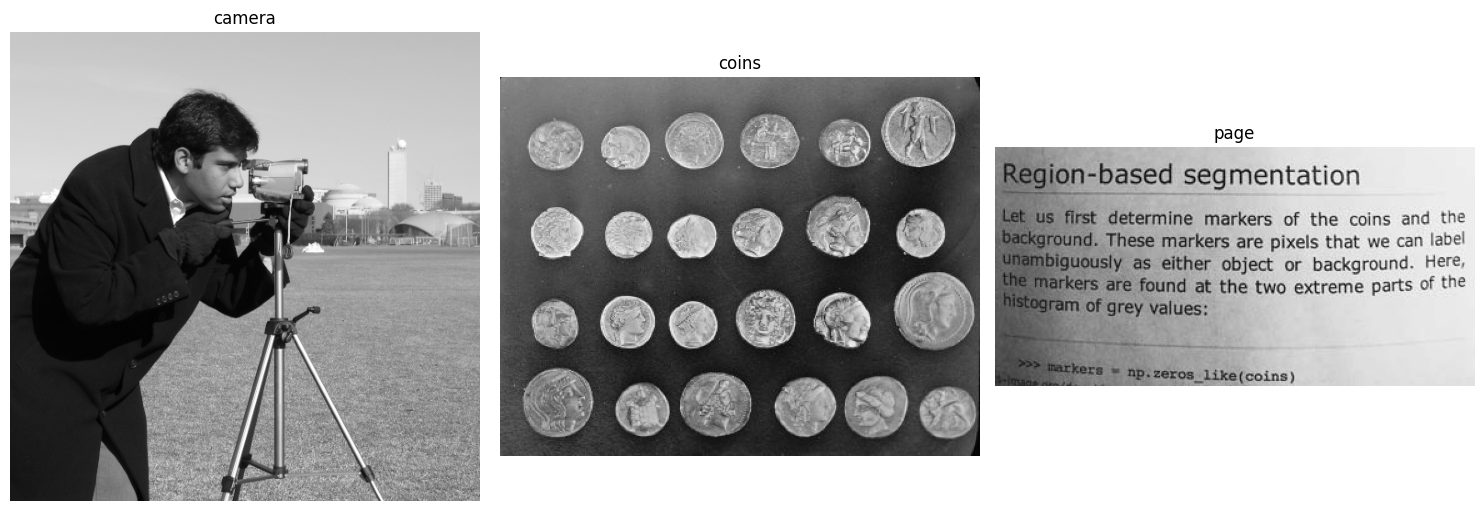

In [ ]:
def show(*images, titles=None, cmaps=None, figsize=(15, 5), vmin=None, vmax=None):
    n = len(images)
    titles = titles or [""] * n
    cmaps = cmaps or [None] * n
    fig, axes = plt.subplots(1, n, figsize=figsize, squeeze=False)
    for ax, image, title, cmap in zip(axes[0], images, titles, cmaps):
        ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def to_float(image):
    image = np.asarray(image)
    if np.issubdtype(image.dtype, np.floating):
        return image.astype(np.float32)
    return image.astype(np.float32) / 255.0


gray = data.camera()
coins = data.coins()
page = data.page()
show(gray, coins, page, titles=["camera", "coins", "page"], cmaps=["gray"] * 3)

## 1. Конечные разности и градиент

На дискретной сетке производную заменяют разностью. Разность вперёд $I[n+1]-I[n]$ имеет ошибку $O(h)$, центральная $\tfrac12(I[n+1]-I[n-1])$ — $O(h^2)$.

Градиент $\nabla I = (I_x, I_y)$:

$$\|\nabla I\| = \sqrt{I_x^2 + I_y^2}, \qquad \theta = \operatorname{atan2}(I_y, I_x).$$

Модуль — сила границы, $\theta$ — направление роста яркости; сама граница перпендикулярна $\theta$.

### Предскажите
На светлом диске на тёмном фоне куда смотрят стрелки градиента — к центру или от центра?

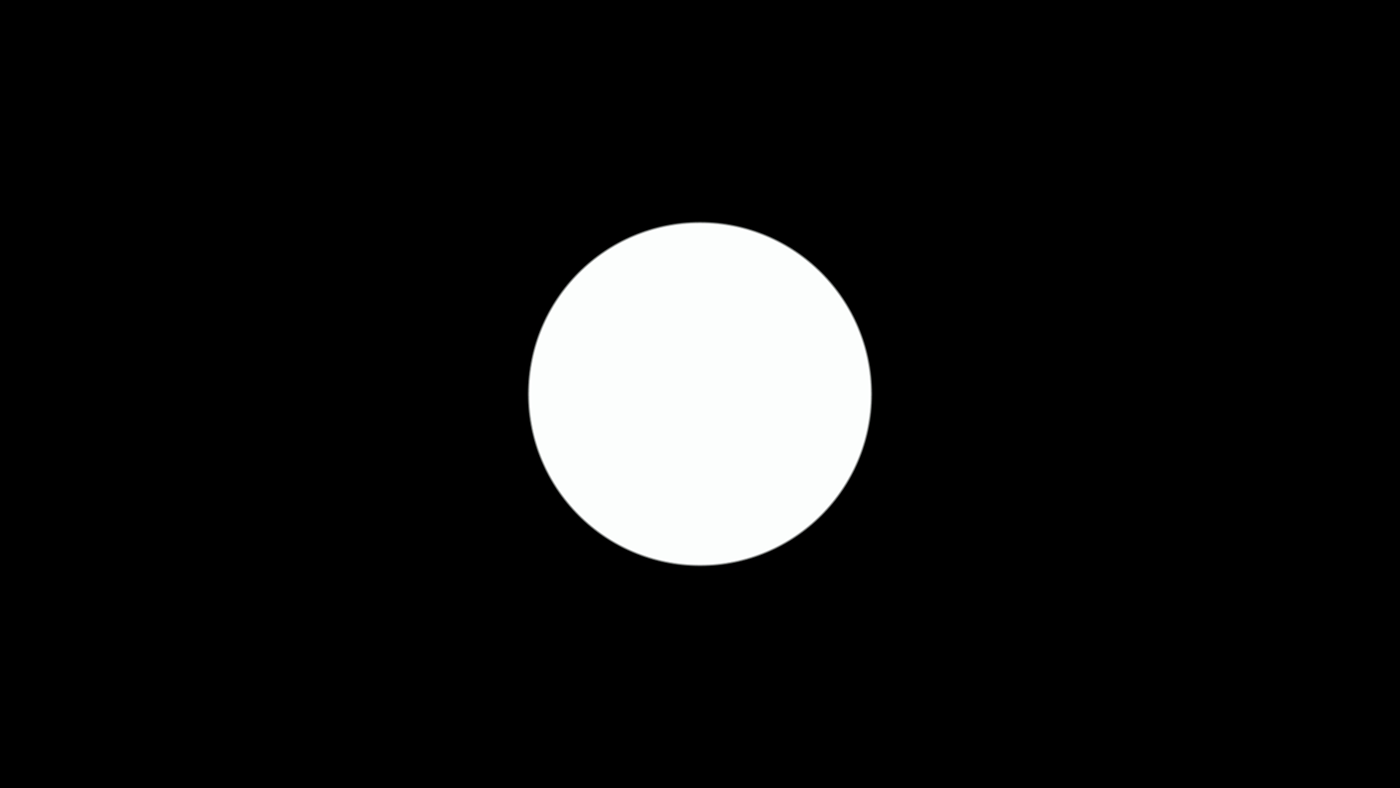

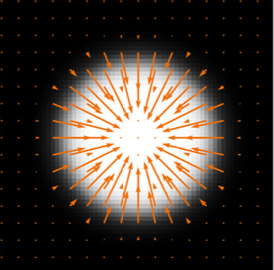

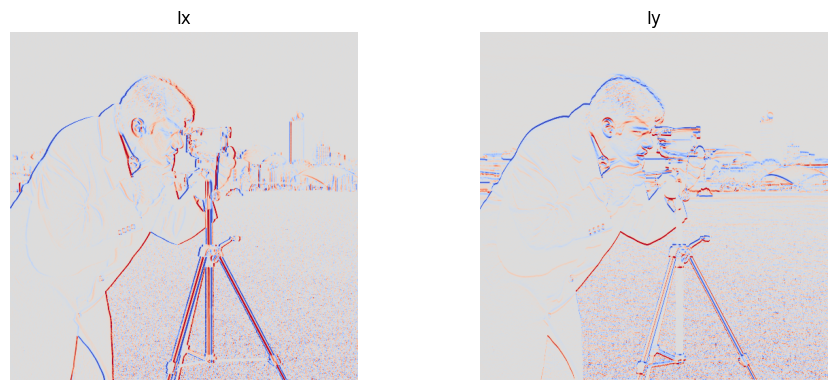

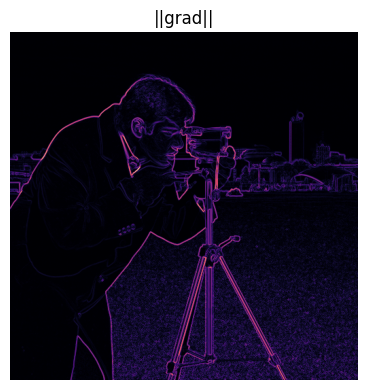

In [ ]:
def central_gradient(image):
    """Центральные разности Ix, Iy, модуль и угол."""
    image = np.asarray(image, dtype=np.float32)
    kx = np.array([[-0.5, 0.0, 0.5]], dtype=np.float32)
    ky = kx.T
    Ix = ndi.correlate(image, kx)
    Iy = ndi.correlate(image, ky)
    mag = np.hypot(Ix, Iy)
    theta = np.arctan2(Iy, Ix)
    return Ix, Iy, mag, theta


I = to_float(gray)
Ix, Iy, mag, theta = central_gradient(I)
show(Ix, Iy, titles=["Ix", "Iy"], cmaps=["coolwarm", "coolwarm"],
     vmin=-0.2, vmax=0.2, figsize=(10, 4))
show(mag, titles=["||grad||"], cmaps=["magma"], figsize=(5, 4))


## 2. Дифференцирование усиливает шум

Для независимого шума дисперсия разности соседей удваивается: $\mathrm{Var}(I[n+1]-I[n]) = 2\sigma^2$. Полезный сигнал разности — лишь локальный перепад, часто мал.

### Предскажите
Добавим к ступеньке шум $\sigma=0.05$. Контур глазом виден. Будет ли он так же хорошо виден на карте $|I[n+1]-I[n]|$ без сглаживания?


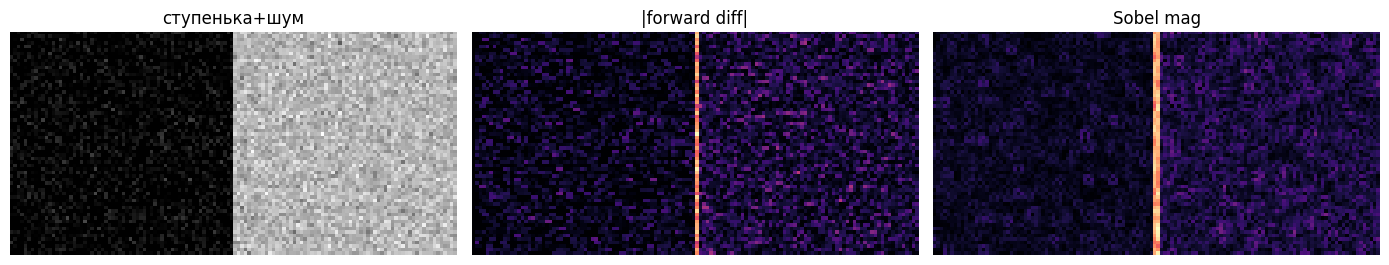

In [ ]:
rng = np.random.default_rng(0)
step = np.zeros((64, 128), dtype=np.float32)
step[:, 64:] = 0.4
noisy = np.clip(step + rng.normal(0, 0.05, step.shape).astype(np.float32), 0, 1)

raw_diff = np.abs(np.diff(noisy, axis=1, prepend=noisy[:, :1]))
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32) / 8.0
Ix_s = ndi.correlate(noisy, kx)
Iy_s = ndi.correlate(noisy, kx.T)
sobel_mag = np.hypot(Ix_s, Iy_s)

show(noisy, raw_diff, sobel_mag,
     titles=["ступенька+шум", "|forward diff|", "Sobel mag"],
     cmaps=["gray", "magma", "magma"], figsize=(14, 4))


## 3. Производная гауссиана и выбор $\sigma$

Сглаживание и дифференцирование можно объединить: $\partial_x(G_\sigma * I) = (\partial_x G_\sigma) * I$.
Параметр $\sigma$ задаёт **масштаб** границ: больше $\sigma$ — меньше шума, но хуже локализация и слияние близких краёв.

В SciPy: `ndi.gaussian_filter(I, sigma, order=(0, 1))` даёт $I_x$, `order=(1, 0)` — $I_y$.

### Предскажите
На узкой светлой полосе шириной 12 пикселей при $\sigma=12$ сколько пиков модуля градиента вы увидите — два или один?


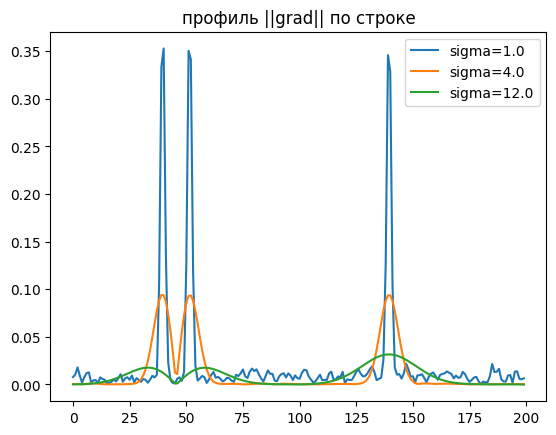

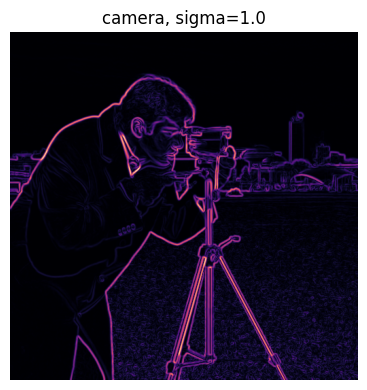

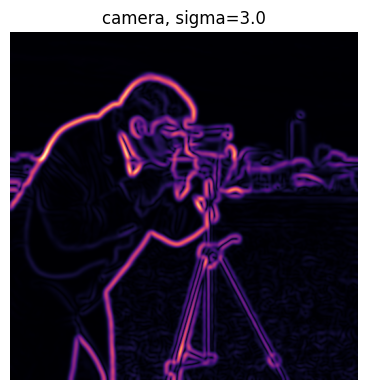

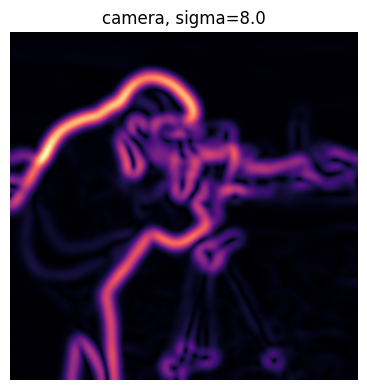

In [ ]:
def gaussian_gradient(image, sigma):
    image = np.asarray(image, dtype=np.float32)
    Ix = ndi.gaussian_filter(image, sigma, order=(0, 1))
    Iy = ndi.gaussian_filter(image, sigma, order=(1, 0))
    mag = np.hypot(Ix, Iy)
    return Ix, Iy, mag


sig = np.zeros((40, 200), dtype=np.float32)
sig[:, 40:52] = 1.0
sig[:, 140:] = 1.0
sig_n = np.clip(sig + rng.normal(0, 0.06, sig.shape).astype(np.float32), 0, 1)

row = 20
for s in (1.0, 4.0, 12.0):
    _, _, mag_s = gaussian_gradient(sig_n, s)
    plt.plot(mag_s[row], label=f"sigma={s}")
plt.legend(); plt.title("профиль ||grad|| по строке"); plt.show()

for s in (1.0, 3.0, 8.0):
    _, _, mag_s = gaussian_gradient(I, s)
    show(mag_s, titles=[f"camera, sigma={s}"], cmaps=["magma"], figsize=(5, 4))


## 4. LoG и пересечения нуля

На границе первая производная максимальна, значит вторая проходит через ноль.
$\nabla^2 G_\sigma * I$ (LoG) или приближение DoG $= G_{k\sigma} - G_\sigma$ при $k\approx 1.6$.

Нули без порога дают «спагетти»; учитывают только смены знака с достаточным перепадом $|L[p]-L[q]| > t$.

### Предскажите
Будут ли нули LoG образовывать замкнутые кривые чаще, чем карта Кэнни?


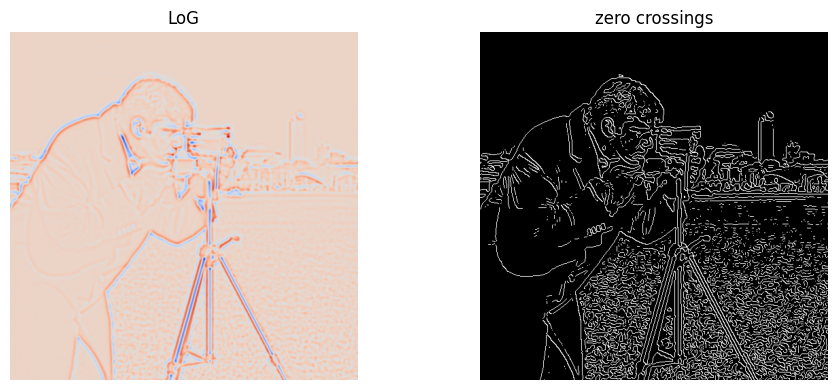

In [ ]:
def log_response(image, sigma):
    return ndi.gaussian_laplace(np.asarray(image, dtype=np.float32), sigma=sigma)


def zero_crossings(log_img, thresh):
    log_img = np.asarray(log_img)
    right = (np.sign(log_img[:, :-1]) != np.sign(log_img[:, 1:])) & (
        np.abs(log_img[:, :-1] - log_img[:, 1:]) > thresh
    )
    down = (np.sign(log_img[:-1, :]) != np.sign(log_img[1:, :])) & (
        np.abs(log_img[:-1, :] - log_img[1:, :]) > thresh
    )
    E = np.zeros(log_img.shape, dtype=bool)
    E[:, :-1] |= right
    E[:-1, :] |= down
    return E


L = log_response(I, sigma=2.0)
E_log = zero_crossings(L, thresh=0.002)
show(L, E_log, titles=["LoG", "zero crossings"], cmaps=["coolwarm", "gray"], figsize=(10, 4))


## 5. Кэнни: подавление немаксимумов (NMS)

После сглаживания модуль градиента — «холм» шириной в несколько пикселей. NMS оставляет пиксель, только если он не меньше соседей **вдоль направления градиента** (поперёк границы).

На практике $\theta$ квантуют в 4 направления: $0^\circ, 45^\circ, 90^\circ, 135^\circ$.

### Предскажите
Что получится, если взять порог по `mag` без NMS — тонкие линии или толстые полосы?


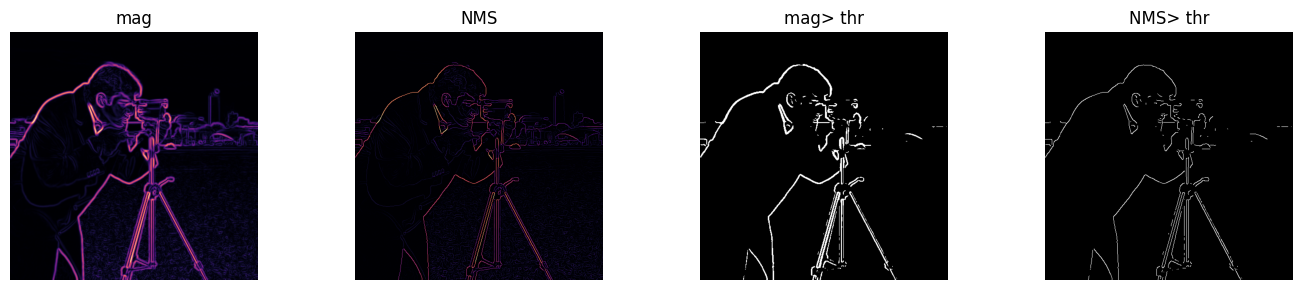

In [ ]:
def nms_4dir(mag, theta):
    """Упрощённый NMS с квантованием угла в 4 направления."""
    mag = np.asarray(mag, dtype=np.float32)
    ang = np.mod(np.asarray(theta, dtype=np.float32), np.pi)
    sector = np.round(ang / (np.pi / 4)).astype(int) % 4
    padded = np.pad(mag, 1, constant_values=-np.inf)
    neighbors = {
        0: (padded[1:-1, 2:], padded[1:-1, :-2]),
        1: (padded[:-2, :-2], padded[2:, 2:]),
        2: (padded[:-2, 1:-1], padded[2:, 1:-1]),
        3: (padded[:-2, 2:], padded[2:, :-2]),
    }
    out = np.zeros_like(mag)
    for s, (n1, n2) in neighbors.items():
        keep = (sector == s) & (mag >= n1) & (mag >= n2)
        out[keep] = mag[keep]
    return out

Ix_g, Iy_g, mag_g = gaussian_gradient(I, sigma=1.5)
theta_g = np.arctan2(Iy_g, Ix_g)
nms = nms_4dir(mag_g, theta_g)
show(mag_g, nms, mag_g > 0.08, nms > 0.08,
     titles=["mag", "NMS", "mag> thr", "NMS> thr"],
     cmaps=["magma", "magma", "gray", "gray"], figsize=(14, 3))


## 6. Кэнни: двойной порог и гистерезис

- сильные: $N[p] \ge T_{\mathrm{high}}$;
- слабые: $T_{\mathrm{low}} \le N[p] < T_{\mathrm{high}}$;
- слабый пиксель остаётся, если связан (8-соседство) с сильным.

Один высокий порог рвёт контуры; один низкий пропускает шум текстуры.

Сравните свой NMS+гистерезис с `feature.canny`.


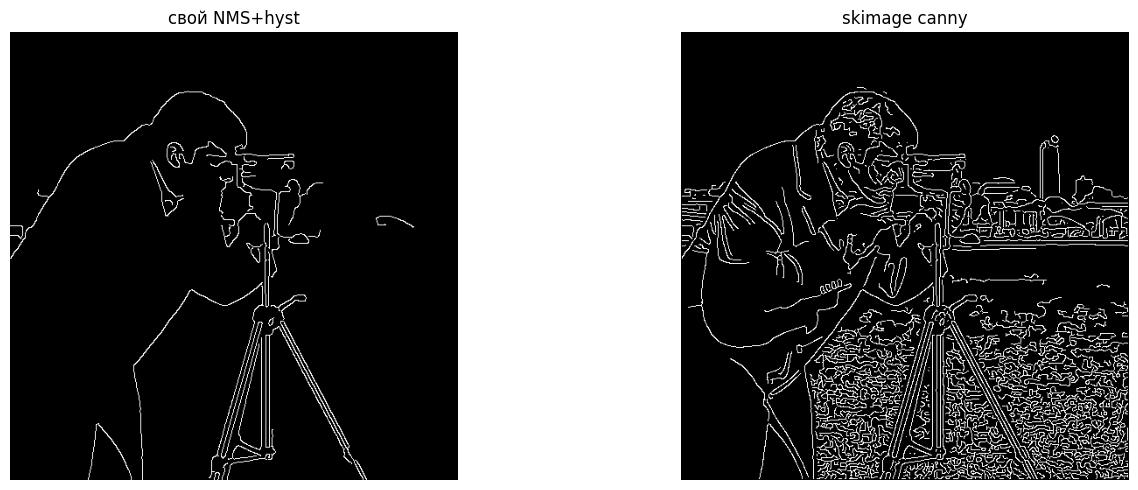

In [ ]:
from collections import deque


def hysteresis(nms_map, t_low, t_high):
    nms_map = np.asarray(nms_map, dtype=np.float32)
    strong = nms_map >= t_high
    weak = (nms_map >= t_low) & ~strong
    out = strong.copy()
    q = deque(zip(*np.nonzero(strong)))
    H, W = nms_map.shape
    while q:
        y, x = q.popleft()
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy == 0 and dx == 0:
                    continue
                ny, nx = y + dy, x + dx
                if 0 <= ny < H and 0 <= nx < W and weak[ny, nx] and not out[ny, nx]:
                    out[ny, nx] = True
                    q.append((ny, nx))
    return out


edges_own = hysteresis(nms, t_low=0.04, t_high=0.10)
edges_sk = feature.canny(I, sigma=1.5, low_threshold=0.04, high_threshold=0.10)
show(edges_own, edges_sk, titles=["свой NMS+hyst", "skimage canny"], cmaps=["gray", "gray"])


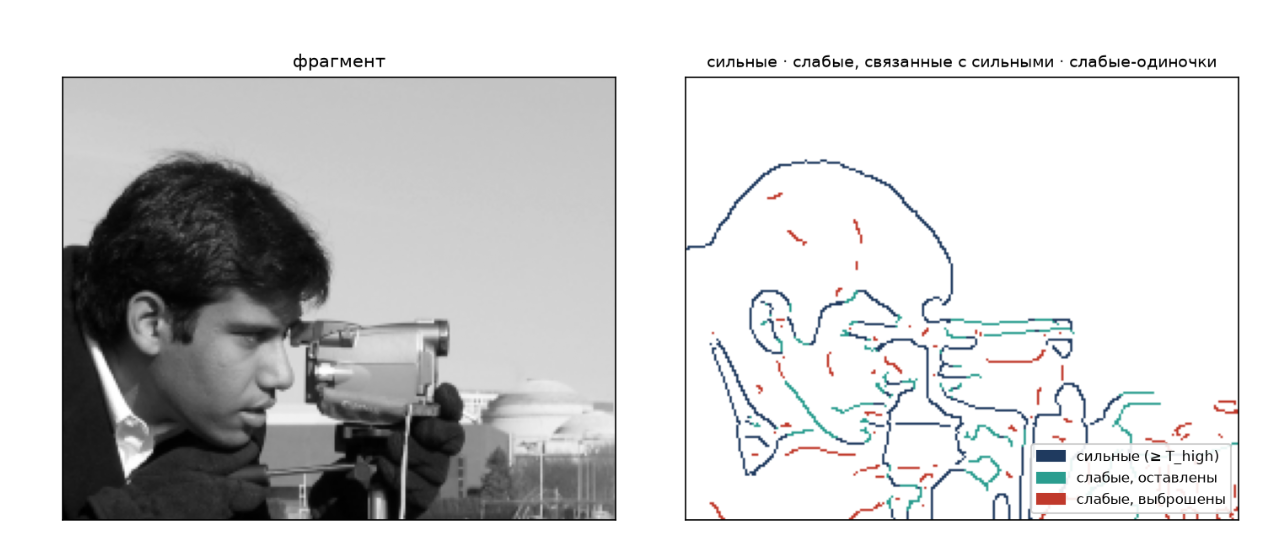

## 7. Преобразование Хафа для прямых

Прямую записывают как $x\cos\theta + y\sin\theta = \rho$, $\theta\in[0,\pi)$.
Каждый пиксель границы голосует за синусоиду в аккумуляторе $A[\theta, \rho]$.

### Предскажите
Если на прямой пропущена половина пикселей, а лишних шумовых точек много, исчезнет ли пик в аккумуляторе?


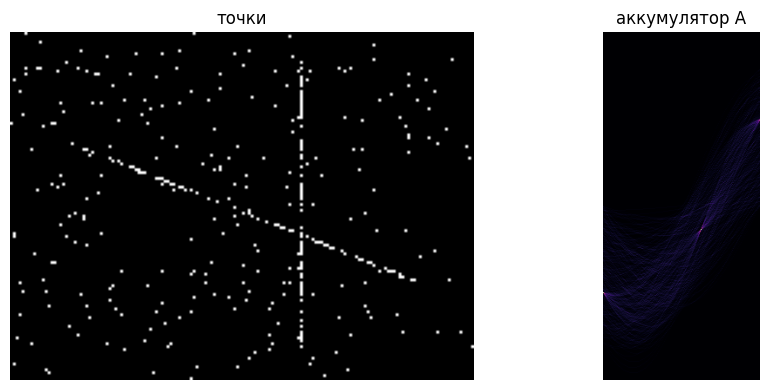

rho=101.0, theta=1.0 deg, votes=32
rho=-99.0, theta=179.0 deg, votes=33
rho=29.0, theta=111.0 deg, votes=36
rho=27.0, theta=112.0 deg, votes=59
rho=100.0, theta=0.0 deg, votes=60


In [ ]:
def hough_lines_accumulate(edge_bool, n_theta=180):
    edge_bool = np.asarray(edge_bool, dtype=bool)
    ys, xs = np.nonzero(edge_bool)
    thetas = np.linspace(0.0, np.pi, n_theta, endpoint=False)
    h, w = edge_bool.shape
    diag = np.hypot(h, w)
    n_rho = int(np.ceil(2 * diag)) + 1
    rhos = np.linspace(-diag, diag, n_rho)
    A = np.zeros((n_rho, n_theta), dtype=np.int32)
    cos_t = np.cos(thetas)
    sin_t = np.sin(thetas)
    for y, x in zip(ys, xs):
        rho_vals = x * cos_t + y * sin_t
        bins = np.clip(np.round((rho_vals - rhos[0]) / (rhos[1] - rhos[0])).astype(int), 0, n_rho - 1)
        A[bins, np.arange(n_theta)] += 1
    return A, thetas, rhos


H, W = 120, 160
canvas = np.zeros((H, W), dtype=bool)
for x in range(20, 140):
    y = int(30 + 0.4 * x)
    if 0 <= y < H:
        canvas[y, x] = True
for y in range(10, 110):
    canvas[y, 100] = True
ys, xs = np.nonzero(canvas)
keep = rng.random(len(xs)) > 0.45
canvas[:, :] = False
canvas[ys[keep], xs[keep]] = True
noise_y = rng.integers(0, H, 250)
noise_x = rng.integers(0, W, 250)
canvas[noise_y, noise_x] = True

A, thetas, rhos = hough_lines_accumulate(canvas)
show(canvas.astype(float), A, titles=["точки", "аккумулятор A"], cmaps=["gray", "magma"], figsize=(10, 4))

flat_idx = np.argpartition(A.ravel(), -5)[-5:]
peaks = np.column_stack(np.unravel_index(flat_idx, A.shape))
for i, j in peaks:
    print(f"rho={rhos[i]:.1f}, theta={np.rad2deg(thetas[j]):.1f} deg, votes={A[i, j]}")


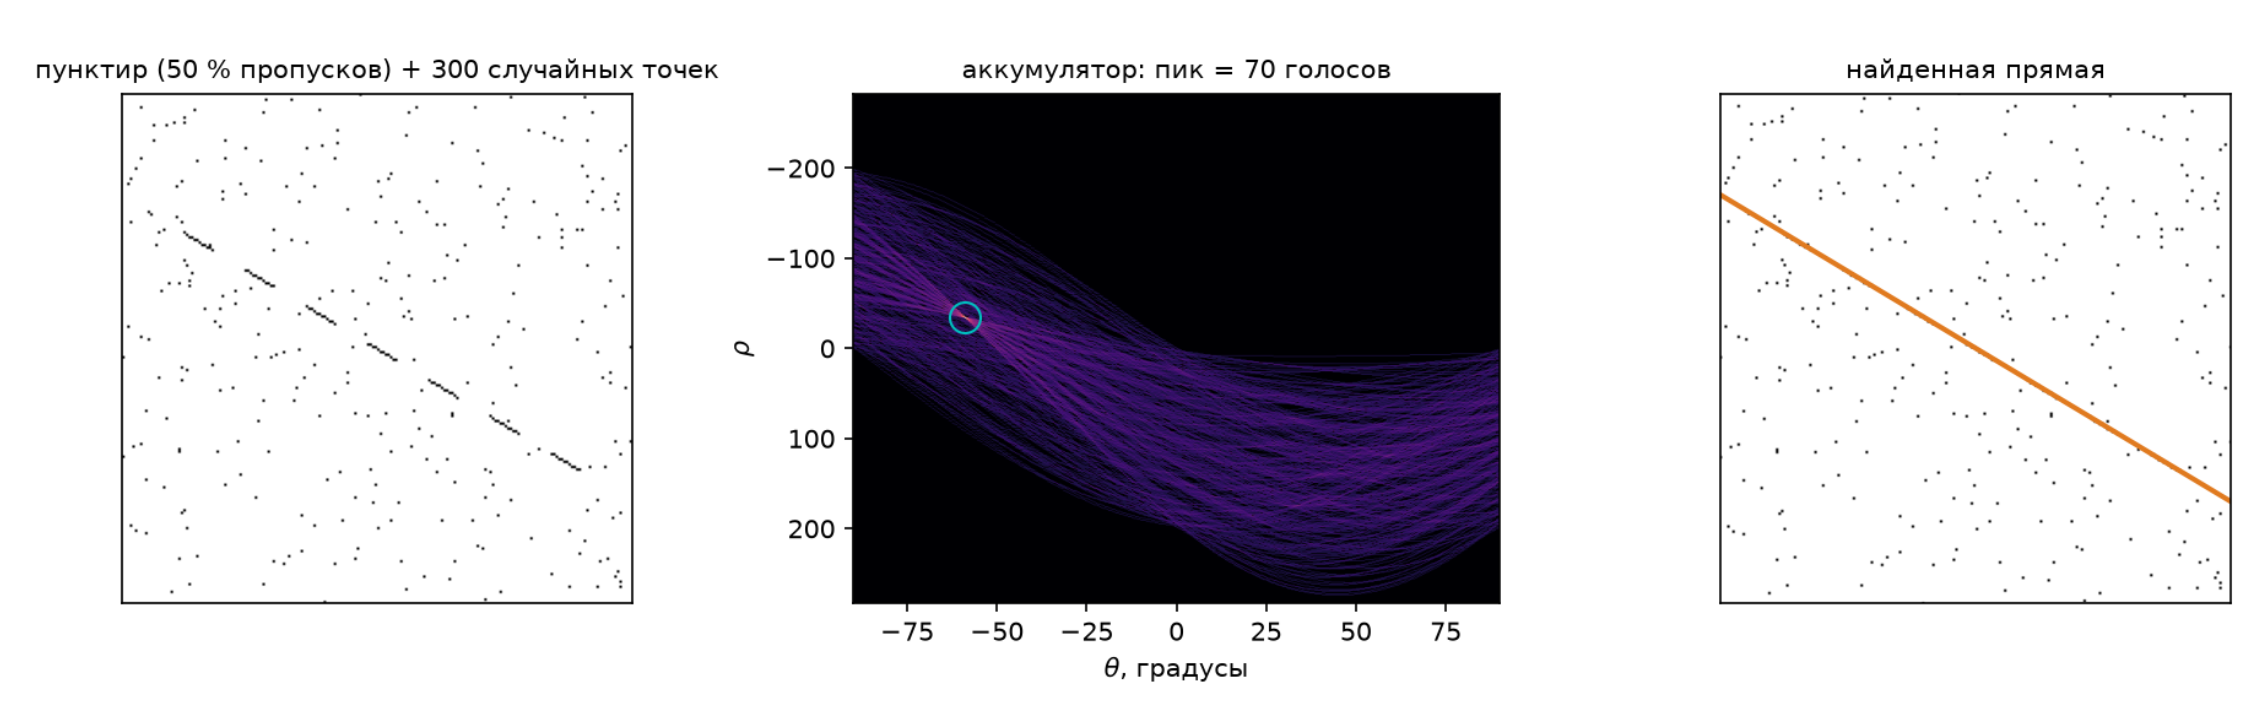

## 8. Хаф для окружностей

$(x-a)^2+(y-b)^2=r^2$ даёт 3D-аккумулятор. Ускорение через градиент:
центр лежит на $(a,b)=(x,y)\pm r(\cos\theta,\sin\theta)$.

На `data.coins()` сравните `cv2.HoughCircles` с визуальной оценкой.


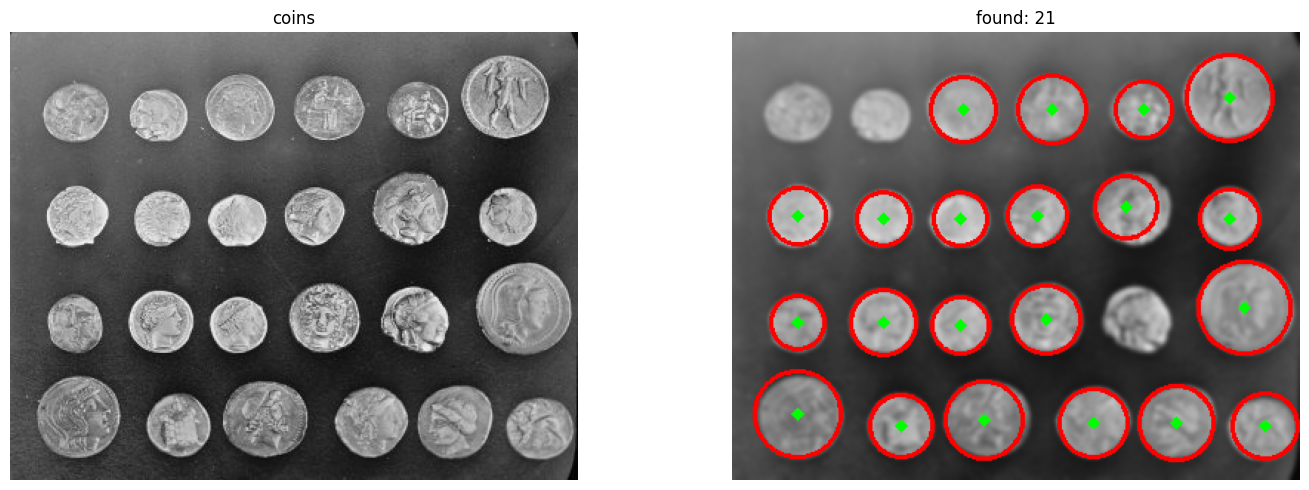

In [ ]:
coins_f = to_float(coins)
coins_blur = ndi.gaussian_filter(coins_f, 1.5)
coins_u8 = util.img_as_ubyte(coins_blur)

circles = cv2.HoughCircles(
    coins_u8,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=20,
    param1=100,
    param2=28,
    minRadius=18,
    maxRadius=42,
)

vis = color.gray2rgb(coins_u8)
if circles is not None:
    for a, b, r in np.round(circles[0]).astype(int):
        cv2.circle(vis, (a, b), r, (255, 0, 0), 2)
        cv2.circle(vis, (a, b), 2, (0, 255, 0), 3)
n_found = 0 if circles is None else circles.shape[1]
show(coins, vis, titles=["coins", f"found: {n_found}"], cmaps=["gray", None])


## 9. Мини-задача: выравнивание документа (deskew)

Строки текста — почти параллельные прямые. Идея:
1. бинаризовать страницу (текст = True);
2. посчитать Хаф только для $\theta\in[60^\circ, 120^\circ]$;
3. $\mathrm{score}(\theta)=\sum_\rho A[\theta,\rho]^2$;
4. наклон $\alpha=\theta^*-90^\circ$, повернуть на $-\alpha$.

Квадрат нужен, потому что без него сумма по $\rho$ одинакова для всех $\theta$.


true tilt ≈ 7.0°, estimated ≈ 6.90°


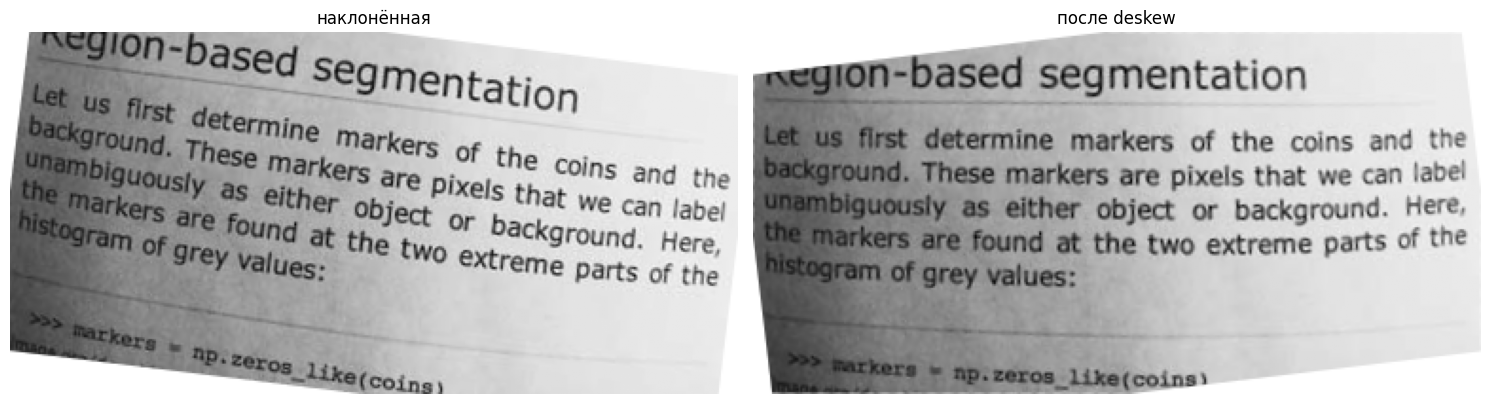

In [11]:
import numpy as np
from skimage import transform


def deskew_angle(binary_text, theta_deg=None):
    """True = текст. Возвращает угол наклона строк в градусах."""
    # Ищем нормали к почти горизонтальным строкам.
    if theta_deg is None:
        theta_deg = np.arange(60.0, 120.0, 0.1) # почему здесь такой диапазон?

    # hough_line принимает углы в радианах.
    thetas = np.deg2rad(theta_deg)

    # A: строки соответствуют расстояниям rho,
    # столбцы — проверяемым углам.
    A, angles, rhos = transform.hough_line(
        binary_text,
        theta=thetas
    )

    # Оцениваем концентрацию голосов для каждого угла.
    # float64 предотвращает переполнение при возведении в квадрат.
    score = (A.astype(np.float64) ** 2).sum(axis=0)

    # Выбираем угол с наиболее выраженной концентрацией.
    best_idx = np.argmax(score)
    theta_star = np.rad2deg(angles[best_idx])

    # Угол нормали переводим в угол наклона строк.
    return float(theta_star - 90.0)

# Искусственный наклон страницы
page_f = to_float(page)
true_tilt = 7.0
# skimage.rotate — против часовой; отрицательный угол даёт положительный deskew
tilted = transform.rotate(page_f, -true_tilt, resize=False, cval=1.0)
# бинаризация: тёмный текст
binary = tilted < filters.threshold_otsu(tilted)

est = deskew_angle(binary)
print(f"true tilt ≈ {true_tilt:.1f}°, estimated ≈ {est:.2f}°")
fixed = transform.rotate(tilted, est, resize=False, cval=1.0)
show(tilted, fixed, titles=["наклонённая", "после deskew"], cmaps=["gray", "gray"])


## 10. Дополнительные задания

1. **Субпиксельная локализация.** По трём значениям модуля вдоль $\theta$ оцените сдвиг $\delta$ параболы и уточните положение границы.
2. **Вероятностный Хаф.** Сравните `cv2.HoughLines` и `cv2.HoughLinesP` на сетке судоку из `data.checkerboard()` или синтетической решётке: где появляются концы отрезков?
3. **DoG ≈ LoG.** Покажите численно, что $G_{k\sigma}-G_\sigma \approx (k-1)\sigma^2 \nabla^2 G_\sigma$ при $k=1.6$.


## Что важно вынести с практики

- граница — место большой производной; детектор не знает её физическую причину;
- дифференцирование усиливает шум → сначала сглаживать (Собель / $\partial G_\sigma$);
- $\sigma$ задаёт масштаб: устойчивость против локализации;
- нули LoG тонки, но дают петли; Кэнни добавляет NMS и гистерезис;
- Хаф устойчив к разрывам и выбросам за счёт голосования, но страдает от размерности параметров;
- deskew страницы — частный случай Хафа по углу строк.
